## Downloading Dependencies

In [1]:
import sys
!conda install --yes --prefix {sys.prefix} numpy
!conda install --yes --prefix {sys.prefix} matplotlib
!conda install --yes --prefix {sys.prefix} pandas
!conda install --yes --prefix {sys.prefix} tensorflow
!conda install --yes --prefix {sys.prefix} scikit-learn

Jupyter detected...
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.



## Importing Libraries

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from keras import layers, losses
from keras.datasets import fashion_mnist
from keras.models import Model

## Basic Autoencoder
Training a basic autoencoder using the Fashion MNIST dataset.

Each image in this dataset is 28x28 pixels

In [8]:
# Load training and test datasets
# _ to ignore the labels (y values)
(x_train, _), (x_test, _) = fashion_mnist.load_data()

# Convert the data types to float32 for NNs
# Normalize the pixel values to range [0,1] by dividing by 255 (since pixel values range from 0 to 255)
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# Print the dimensions o the dataset
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


Therefore we know that the

Training dataset has 60k images of dimensions 28x28
Test dataset has 10k images of dimensions 28x28

Now we will define an autoencoder with two Dense layers (encoder and decoder) using the Keras Model Subclassing API.

*A dense layer, also known as a fully connected layer, is a type of neural network layer where each neuron in the layer is connected to every neuron in the previous layer.*

In [13]:
# Subclass the keras model to control how it behaves
class Autoencoder(Model):
    
    def __init__(self, latent_dim, shape):
        # Initiliase the base class
        super(Autoencoder, self).__init__()
        # Extend the initilisastion with the encoded representation and the shape (dimensions)
        self.latent_dim = latent_dim
        self.shape = shape
        # Extend the initilisation with the encoder and decoder layers
        self.encoder = tf.keras.Sequential([
            # Flatten to single dimension
            layers.Flatten(),
            # Connect to a Dense Layer with ReLU activation
            layers.Dense(latent_dim, activation='relu')
        ])
        self.decoder = tf.keras.Sequential([
            # Expand the latent_dim back to original
            # By multipling the dimensions with reduce_prod and converting the Tensor to an int with numpy
            # Sigmoid to ensure output is within 0 and 1
            layers.Dense(tf.math.reduce_prod(shape).numpy(), activation='sigmoid'),
            # Reshape to convert the flat back into an image shape (2 dimension)
            layers.Reshape(shape)
        ])

    def call(self, x):
        # Defines the feedforward
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

shape = x_test.shape[1:] # Slice the tuple to define shape as (28, 28)
latent_dim = 64 # Define latent dimension to 64 (in 1d) so 28x28=784 reduced to 64
autoencoder = Autoencoder(latent_dim, shape) # Create the instance

Now we can configure the model for training and start the training process

We are using "adam" which is a optimization algorithm that adapts learning rates during training.

For the loss function, we are using Mean Squared Error (MSE).
Due to the nature of encoders, we want as little "loss" as possible for better reconstruction.
MSE squares the pixel difference which *emphasiszes* the difference hence larger mistakes count more (or penalized more), which means the models will focus on fixing the worse reconstructions to reduce the "loss".

In [16]:
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

# Train the model with the training dataset as both the input and target since the model is learning to reproduce its input (think of target as labels)
# 10 epochs -> pass through the entire training dataset 10 times
# Randomly shuffle the data each epoch for generalization
# During training, validate with the test dataset as input and target after each epoch
autoencoder.fit(
    x_train, x_train,
    epochs=10,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 734us/step - loss: 0.0398 - val_loss: 0.0132
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 683us/step - loss: 0.0122 - val_loss: 0.0106
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 685us/step - loss: 0.0103 - val_loss: 0.0097
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 680us/step - loss: 0.0096 - val_loss: 0.0097
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 692us/step - loss: 0.0093 - val_loss: 0.0092
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 680us/step - loss: 0.0090 - val_loss: 0.0090
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 694us/step - loss: 0.0089 - val_loss: 0.0090
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 676us/step - loss: 0.0088 - val_loss: 0.0090
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 679us/step - loss: 0.0088 - val_loss: 0.0088
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 703us/step - loss: 0.0087 - val_loss: 0.0088


Now that the model is training, we  can test it.

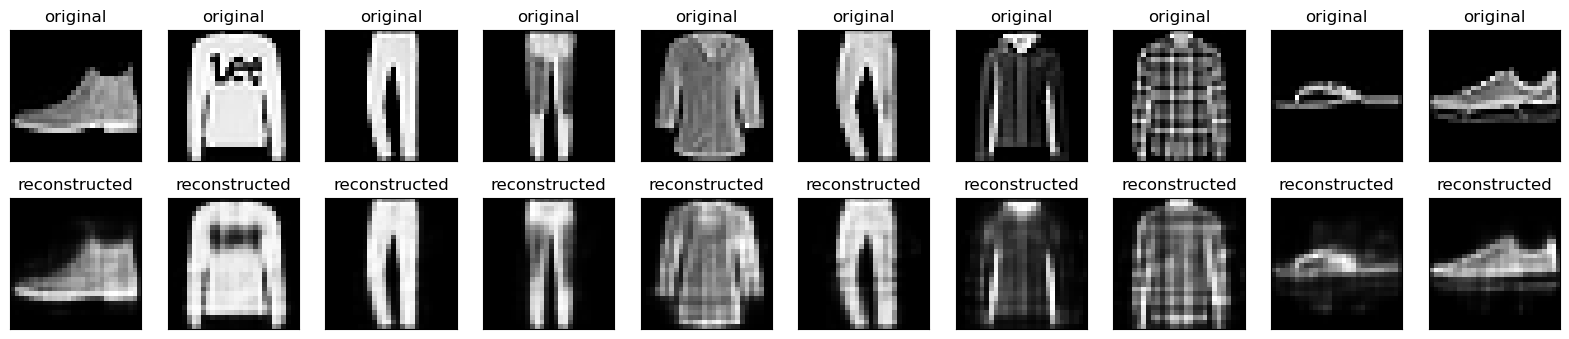

In [18]:
# Encode/Decode the image and convert from Tensor to NumPy array 
encoded_imgs = autoencoder.encoder(x_test).numpy()
decoded_imgs = autoencoder.decoder(encoded_imgs).numpy()

# Now to visualize the images, we define 10 pictures for original and 10 for reconstruction
# We fit it into a  figure of size 20x4 inches
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i+1) # Arranges the images in a 2-row, n-column grid
    plt.imshow(x_test[i])
    plt.title("original")
    plt.gray() # Grayscale
    # Hide the axis ticks
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstruction
    ax = plt.subplot(2, n, i+1+n) # After first 10 in same 2-row, n-column grid
    plt.imshow(decoded_imgs[i])
    plt.title("reconstructed")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    
plt.show()

## Image Denoising Autoencoder
Now we will train an autoencoder to remove noise from images.

First we will add some noise to the dataset

In [20]:
(x_train, _), (x_test, _) = fashion_mnist.load_data()

x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

# Add New Dimension (The Keras Layer used later requries 4D)
# We are adding the channel dimension)
x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]

print(x_train.shape)

(60000, 28, 28, 1)


In [21]:
# Adding Noise
noise_factor = 0.2
# Create a new tensor of same shape with random values drawn from a normal distribution [-1, 1]
# Scale the random noise to something smaller [-0.2, 0.2]
# Add it back to the original
x_train_noisy = x_train + noise_factor * tf.random.normal(shape=x_train.shape)
x_test_noisy = x_test + noise_factor * tf.random.normal(shape=x_test.shape)

# After adding noise, some pixel values might go below 0 or above 1 which is not valid
# So we clip it to ensure every pixel is between 0 and 1
x_train_noisy = tf.clip_by_value(x_train_noisy, clip_value_min=0., clip_value_max=1.)
x_test_noisy = tf.clip_by_value(x_test_noisy, clip_value_min=0., clip_value_max=1.)

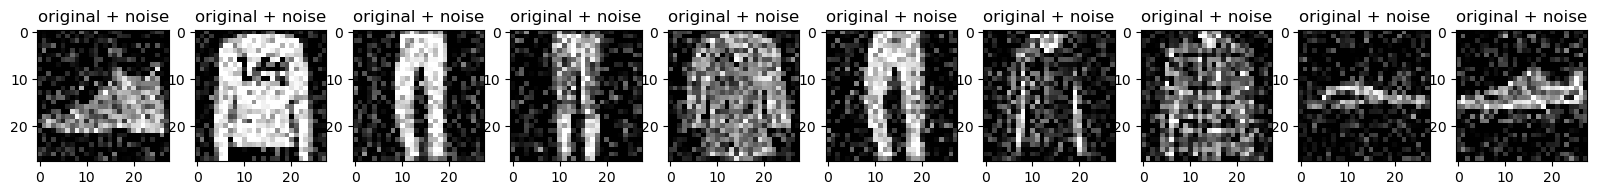

In [22]:
# Plotting the noisy images
n = 10
plt.figure(figsize=(20, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.title("original + noise")
    plt.imshow(tf.squeeze(x_test_noisy[i]))
    plt.gray()
plt.show()

Now we will define a convolutional autoencoder using Conv2D layers in the encoder and Conv2DTranspose layers in the decoder.

In [25]:
class Denoise(Model):
    def __init__(self):
        super(Denoise, self).__init__()
        self.encoder = tf.keras.Sequential([
          layers.Input(shape=(28, 28, 1)),
          # 16 Filters, 3x3 Kernel, stride=2 to halve the image size (14,14,16)
          # 16 Filters means 16 channels i.e. RGB is 3 colour channels
          # 3x3 kernel means we look at 3x3 region at a time
          # Stride 2 means kernel moves 2 pixels at a time (skips every other 3x3 tile) instead of 1 thereby halving the size
          layers.Conv2D(16, (3, 3), activation='relu', padding='same', strides=2),
          # (7,7,8)
          layers.Conv2D(8, (3, 3), activation='relu', padding='same', strides=2)
        ])

        self.decoder = tf.keras.Sequential([
          # Does the reverse, upsamples from (7,7,8) to (14,14,8)
          layers.Conv2DTranspose(8, kernel_size=3, strides=2, activation='relu', padding='same'),
          # (14,14,8) to (28,28,16)
          layers.Conv2DTranspose(16, kernel_size=3, strides=2, activation='relu', padding='same'),
          # Reduce channel from 16 to 1 (grayscale)
          layers.Conv2D(1, kernel_size=(3, 3), activation='sigmoid', padding='same')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

autoencoder = Denoise()

Now we can train the model

In [26]:
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

In [27]:
autoencoder.fit(x_train_noisy, x_train,
                epochs=10,
                shuffle=True,
                validation_data=(x_test_noisy, x_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0388 - val_loss: 0.0101
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0098 - val_loss: 0.0089
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0086 - val_loss: 0.0083
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0082 - val_loss: 0.0079
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0078 - val_loss: 0.0076
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0075 - val_loss: 0.0074
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0074 - val_loss: 0.0073
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0073 - val_loss: 0.0073
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0072 - val_loss: 0.0072
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0072 - val_loss: 0.0071


Let's take a look at a summary of the encoder. Notice how the images are downsampled from 28x28 to 7x7.

In [28]:
autoencoder.encoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 8)        │         1,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,320 (5.16 KB)

 Trainable params: 1,320 (5.16 KB)

 Non-trainable params: 0 (0.00 B)

The decoder upsamples the images back from 7x7 to 28x28.

In [29]:
autoencoder.decoder.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_transpose                │ (32, 14, 14, 8)        │           584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (32, 28, 28, 16)       │         1,168 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 28, 28, 1)        │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,897 (7.41 KB)

 Trainable params: 1,897 (7.41 KB)

 Non-trainable params: 0 (0.00 B)

Now we can plot both the noisy images and the denoised images produced by the autoencoder

In [32]:
encoded_imgs = autoencoder.encoder(x_test_noisy).numpy()
decoded_imgs = autoencoder.decoder(encoded_imgs).numpy()

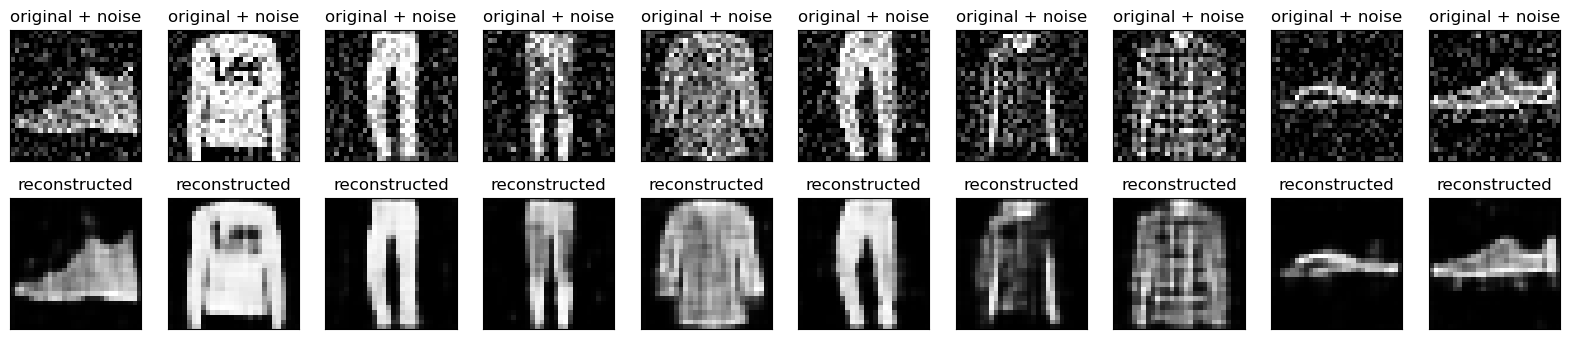

In [33]:
# Plotting
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):

    # display original + noise
    ax = plt.subplot(2, n, i + 1)
    plt.title("original + noise")
    plt.imshow(tf.squeeze(x_test_noisy[i]))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # display reconstruction
    bx = plt.subplot(2, n, i + n + 1)
    plt.title("reconstructed")
    plt.imshow(tf.squeeze(decoded_imgs[i]))
    plt.gray()
    bx.get_xaxis().set_visible(False)
    bx.get_yaxis().set_visible(False)
plt.show()

## Anomaly Detection
Finally, we will train an autoencoder to detect aomalies on the ECG5000 dataset. This dataset contains 5,000 Electrocardiograms, each with 140 data points. We will use a simplified version of the dataset, where each example has been labeled either 0 (corresponding to an abnormal rhythm), or 1 (corresponding to a normal rhythm). 

We will train an autoencoder on the normal rhythms only, then use it to reconstruct all the data. Our hypothesis is that the abnormal rhythms will have higher reconstruction error. We will then classify a rhythm as an anomaly if the reconstruction error surpasses a fixed threshold.

First we will load the ECG data

In [36]:
dataframe = pd.read_csv('http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv', header=None)
raw_data = dataframe.values
dataframe.head() # Display Top 5 values

,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [50]:
# We can see the last column contains the labels (so we extract it)
labels = raw_data[:,-1]

# The rest of the point are the electrocardiogram data
data = raw_data[:,0:-1]

# Split the dataset for training and testing
train_data, test_data, train_labels, test_labels = train_test_split(
    data, labels, test_size=0.2, random_state=21
)

Normalize for a standard scale for the neural networks

In [51]:
# First find the min and max values
min_val = tf.reduce_min(train_data)
max_val = tf.reduce_max(train_data)

# Normalize
train_data = (train_data - min_val) / (max_val - min_val)
test_data = (test_data - min_val) / (max_val - min_val)

# Convert the data type to float32
train_data = tf.cast(train_data, tf.float32)
test_data = tf.cast(test_data, tf.float32)

Separate the normal rhythms from the abnormal rhytms

In [52]:
# Convert into True or False (booleans)
train_labels = train_labels.astype(bool)
test_labels = test_labels.astype(bool)

# Select the data points that is True (or normal)
normal_train_data = train_data[train_labels]
normal_test_data = test_data[test_labels]

# Negation for the opposite
anomalous_train_data = train_data[~train_labels]
anomalous_test_data = test_data[~test_labels]

Plot a normal ECG

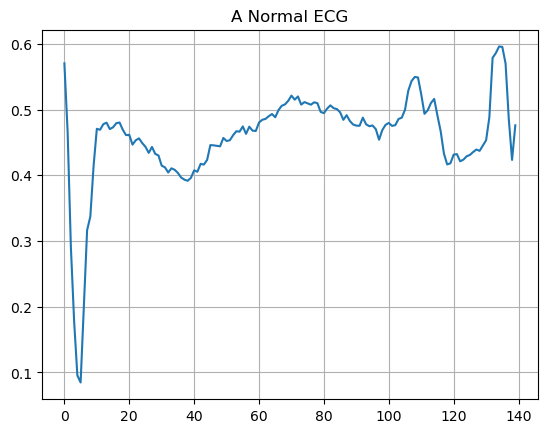

In [53]:
plt.grid()
# Create a range of values from 0 to 139 (140 total) on the x-axis
# First row of normal_train_data on the y-axis
plt.plot(np.arange(140), normal_train_data[0])
plt.title("A Normal ECG")
plt.show()

Plot an anomalous ECG

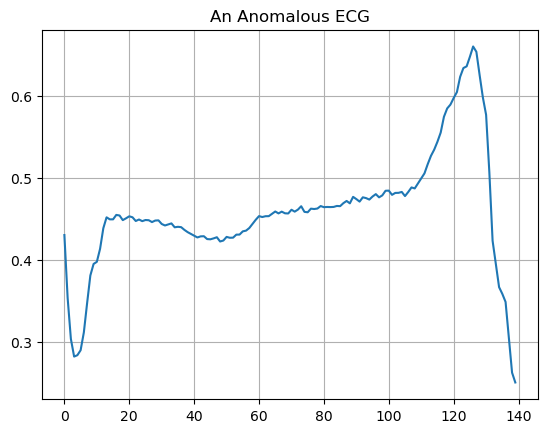

In [54]:
plt.grid()
plt.plot(np.arange(140), anomalous_train_data[0])
plt.title("An Anomalous ECG")
plt.show()

Now with an understanding of the data and the data prepared, we can build the model

In [55]:
class AnomalyDetector(Model):
  def __init__(self):
    super(AnomalyDetector, self).__init__()
    self.encoder = tf.keras.Sequential([
      # For better learning we don't reduce straight to 8
      layers.Dense(32, activation="relu"),
      layers.Dense(16, activation="relu"),
      layers.Dense(8, activation="relu")])

    self.decoder = tf.keras.Sequential([
      # For better learning we don't expand straight to 140
      layers.Dense(16, activation="relu"),
      layers.Dense(32, activation="relu"),
      layers.Dense(140, activation="sigmoid")])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

autoencoder = AnomalyDetector()

In [57]:
autoencoder.compile(optimizer='adam', loss='mae')

In [58]:
history = autoencoder.fit(normal_train_data, normal_train_data,
          epochs=20,
          batch_size=512, #Number of training samples model processes before updating its weights during training
          validation_data=(test_data, test_data),
          shuffle=True)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0581 - val_loss: 0.0531
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0557 - val_loss: 0.0509
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0526 - val_loss: 0.0483
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0484 - val_loss: 0.0458
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0434 - val_loss: 0.0445
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0393 - val_loss: 0.0429
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0358 - val_loss: 0.0404
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0327 - val_loss: 0.0391
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0302 - val_loss: 0.0386
Epoch 10/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0284 - val_loss: 0.0376
Epoch 11/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0269 - val_loss: 0.0371
Epoch 12/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0259 - val_loss: 0.0366
Epoch 13/20


To visualize the loss (or the measure of the model
s predictions) during the training process

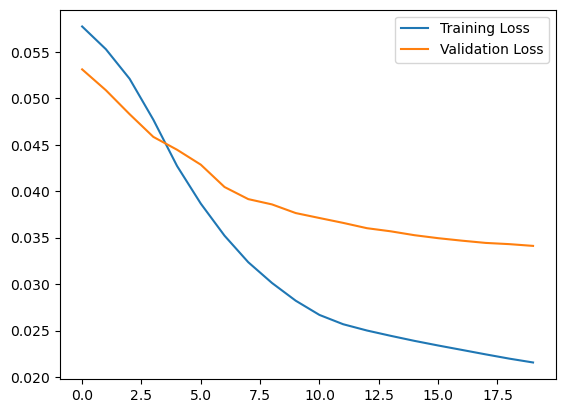

In [59]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()

Now we can plot a normal ECG from the training set, the reconstruction after it's encoded and decoded by the autoencoder, and the reconstruction error.

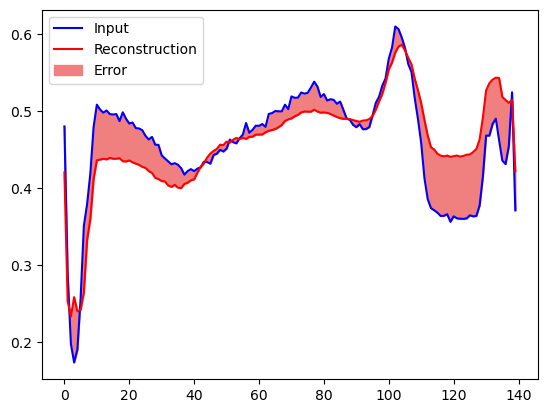

In [60]:
encoded_data = autoencoder.encoder(normal_test_data).numpy()
decoded_data = autoencoder.decoder(encoded_data).numpy()

plt.plot(normal_test_data[0], 'b') # Plot in blue
plt.plot(decoded_data[0], 'r') # Plot in red
# Fill space between the curves with light red
plt.fill_between(np.arange(140), decoded_data[0], normal_test_data[0], color='lightcoral')
plt.legend(labels=["Input", "Reconstruction", "Error"])
plt.show()

We repeat but this time for an anomalous test example.

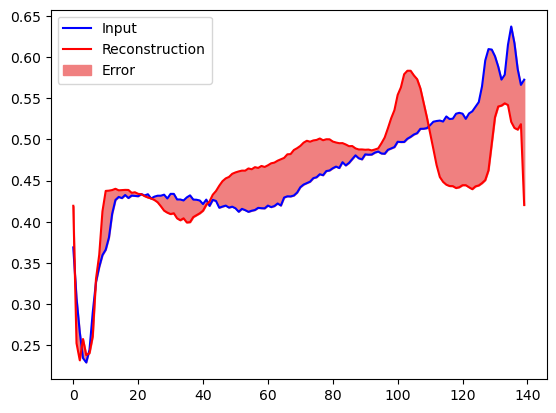

In [61]:
encoded_data = autoencoder.encoder(anomalous_test_data).numpy()
decoded_data = autoencoder.decoder(encoded_data).numpy()

plt.plot(anomalous_test_data[0], 'b')
plt.plot(decoded_data[0], 'r')
plt.fill_between(np.arange(140), decoded_data[0], anomalous_test_data[0], color='lightcoral')
plt.legend(labels=["Input", "Reconstruction", "Error"])
plt.show()

We can observe the error and differences to be more jarring in the anomalous example.

Therefore we can detect anomalies by calculating whether the reconstruction loss is greater than a fixed threshold.

First we need determine the threshold. To do so, we can plot the reconstruction error on normal ECGs from the training set

74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 379us/step


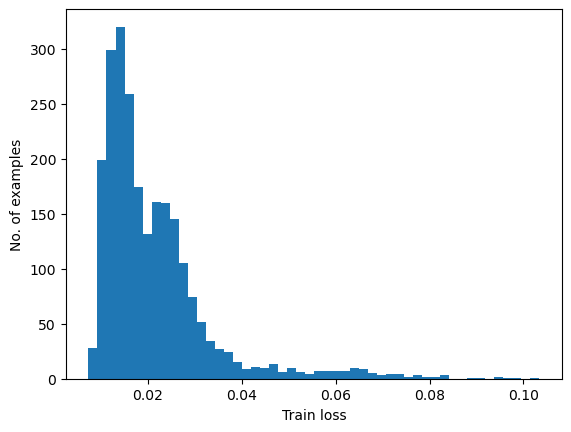

In [64]:
reconstructions = autoencoder.predict(normal_train_data)
train_loss = tf.keras.losses.mae(reconstructions, normal_train_data)

plt.hist(train_loss[None,:], bins=50)
plt.xlabel("Train loss")
plt.ylabel("No. of examples")
plt.show()

 Now we can choose a threshold value that is one standard deviations above the mean

 *Note: There are other strategies to select an appropriate threshold value which depends on the dataset*

In [65]:
threshold = np.mean(train_loss) + np.std(train_loss)
print("Threshold: ", threshold)

Threshold:  0.033659432


If we examine the reconstruction error for the anomalous examples in the test set, you'll notice most have greater reconstruction error than the threshold. By varing the threshold, we can adjust the precision and recall of your classifier.

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 493us/step


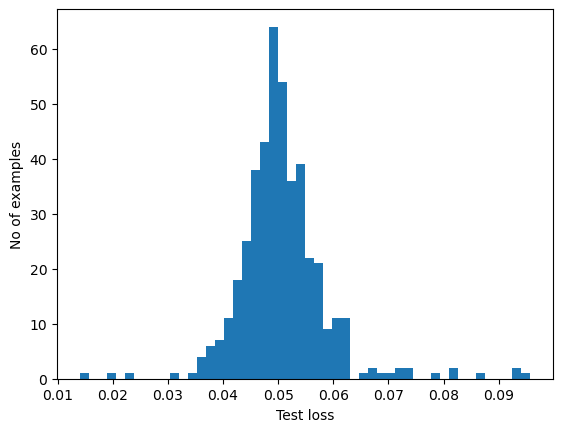

In [67]:
reconstructions = autoencoder.predict(anomalous_test_data)
test_loss = tf.keras.losses.mae(reconstructions, anomalous_test_data)

# Plot a histogram, we add an extra axis to the 1D test_loss array with None to become 2D
# Bins is the number of intervals for the histogram
plt.hist(test_loss[None, :], bins=50)
plt.xlabel("Test loss")
plt.ylabel("No of examples")
plt.show()

With our threshold defined, we can classify an ECG as an anomaly if the reconstruction error is greater than the threshold.

In [68]:
def predict(model, data, threshold):
    reconstructions = model(data)
    loss = tf.keras.losses.mae(reconstructions, data)
    # Detects if value lower than threshold then return true else false
    return tf.math.less(loss, threshold)

def print_stats(predictions, labels):
    print("Accuracy = {}".format(accuracy_score(labels, predictions)))
    print("Precision = {}".format(precision_score(labels, predictions)))
    print("Recall = {}".format(recall_score(labels, predictions)))

In [69]:
preds = predict(autoencoder, test_data, threshold)
print_stats(preds, test_labels)

Accuracy = 0.944
Precision = 0.9921875
Recall = 0.9071428571428571


## Other resources
https://anomagram.fastforwardlabs.com/#/           
https://blog.tensorflow.org/2020/04/how-airbus-detects-anomalies-iss-telemetry-data-tfx.html             
https://blog.keras.io/building-autoencoders-in-keras.html              
https://www.deeplearningbook.org/           